# **Dataset Quality Checking**


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#import required libraries
from pathlib import Path
from PIL import Image
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

# setting the seed for reproducible random image sampling
random.seed(42)

In [ ]:
#defining dataset paths
datasets = {
    "Montgomery": Path('/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/Montgomery/CXR_png'),
    "Shenzhen": Path('/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/Shenzhen/CXR_png'),
    "NIH": Path("/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted")
} #due to size, NIH will be processed seperately
for name, path in datasets.items():
  if path.exists():
    print(f'{name} Found')
  else:
    print('Path not found')


Montgomery Found
Shenzhen Found
NIH Found


In [ ]:
#counting images found in datasets for comparisson with corrupy/duplicate images later
dataset_files = {} #storing in variable to avoid repetition later on to improve speed

for dataset_name, dataset_path in datasets.items():
  img_files = [
      file for file in dataset_path.rglob("*")
      if file.is_file() and file.suffix.lower() == ".png"
  ]

  dataset_files[dataset_name] = img_files
  print(f'{dataset_name}: {len(img_files)}')


Montgomery: 138
Shenzhen: 662
NIH: 112120


In [ ]:
#define function to check for corrupt images
def check_corrupt(f_path):
  try:
    with Image.open(f_path) as img:
      img.verify()
    return "Uncorrupted"

  except Exception as e:
    return (f'Corrupted: {e}')

In [ ]:
#checking all datasets for corrupt images
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def check_file(file_info):
  dataset_name, file_path = file_info
  status = check_corrupt(file_path)
  return{
      "Dataset": dataset_name,
      "File": str(file_path),
      "Status": status
  }

#list to store all images across all datasets
all_files = [
    (dataset_name, file_path)
    for dataset_name, img_files in dataset_files.items()
    for file_path in img_files
]

print(f'Total images to validate: {len(all_files)}')

corrupt_results = []

with ThreadPoolExecutor(max_workers=12) as executor:
  for result in tqdm(
      executor.map(check_file, all_files),
      total = len(all_files),
      desc = "Checking images for corruption"
  ):
    corrupt_results.append(result)

integrity_report = pd.DataFrame(corrupt_results)
integrity_report["Status"].apply(lambda x:"Corrupted" if x.startswith("Corrupted") else "Uncorrupted").value_counts()

Total images to validate: 112920


Exception ignored in: <function tqdm.__del__ at 0x79572fceac00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tqdm/std.py", line 1148, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/tqdm/notebook.py", line 280, in close
    self.disp(bar_style='success', check_delay=False)
AttributeError: 'tqdm' object has no attribute 'disp'


Checking images for corruption:   0%|          | 0/112920 [00:00<?, ?it/s]

,count
Status,
Uncorrupted,112920


All files can be opened, indicating low chances of corruption, random sampling will be used to view image quality later.

In [ ]:
#identifying unique file sizes vs file sizes shared by many images to speed up exact duplicate detection
from collections import defaultdict

size_groups = defaultdict(list)

for dataset_name, img_files in dataset_files.items():
  for file_path in img_files:
    file_size = file_path.stat().st_size
    size_groups[file_size].append({
        "Dataset": dataset_name,
        "File": file_path
    })
repeating_candidates = {
    size: files
    for size, files in size_groups.items()
    if len(files) > 1
}
print(f'Total unique file sizes: {len(size_groups)}')
print(f'File sizes shared by multiple images: {len(repeating_candidates)}')

Total unique file sizes: 76060
File sizes shared by multiple images: 26874


In [ ]:
#Exact duplicate detection function
CHUNK_SIZE = 1024*1024
def get_img_hash(file_path):
  img_hash = hashlib.md5()

  with open(file_path, "rb") as f:
    for chunk in iter(lambda: f.read(CHUNK_SIZE), b""): #processing images in chunks to deal with potentially large files
      img_hash.update(chunk)

  return img_hash.hexdigest() #returns final hash

In [ ]:
# find exact duplicates across all datasets

#calculate hash for each image and store results in dataset
hash_results = []

potential_dupes = [
    file_info
    for files in repeating_candidates.values()
    for file_info in files
]
print(f'Images needing hash checks: {len(potential_dupes)}')

with ThreadPoolExecutor(max_workers=12) as executor:
  for result in tqdm(
      executor.map(
          lambda x: {
              "Dataset": x["Dataset"],
              "File": str(x["File"]),
              "Hash": get_img_hash(x["File"])
          },
          potential_dupes
      ),
      total = len(potential_dupes),
      desc = "Calculating image Hash"
  ):
    hash_results.append(result)

hash_results = pd.DataFrame(hash_results)
hash_results.head(4)

#find duplicate matches and group them
duplicates = hash_results[
    hash_results.duplicated(
        subset = "Hash",
        keep = False
    )].copy()

duplicates["FileName"] = duplicates["File"].apply(lambda x: Path(x).name)

duplicates[["Dataset","File","Hash"]].sort_values("Hash")

Images needing hash checks: 63734


Calculating image Hash:   0%|          | 0/63734 [00:00<?, ?it/s]

,Dataset,File,Hash


Duplicate df empty indicating no exact duplicates

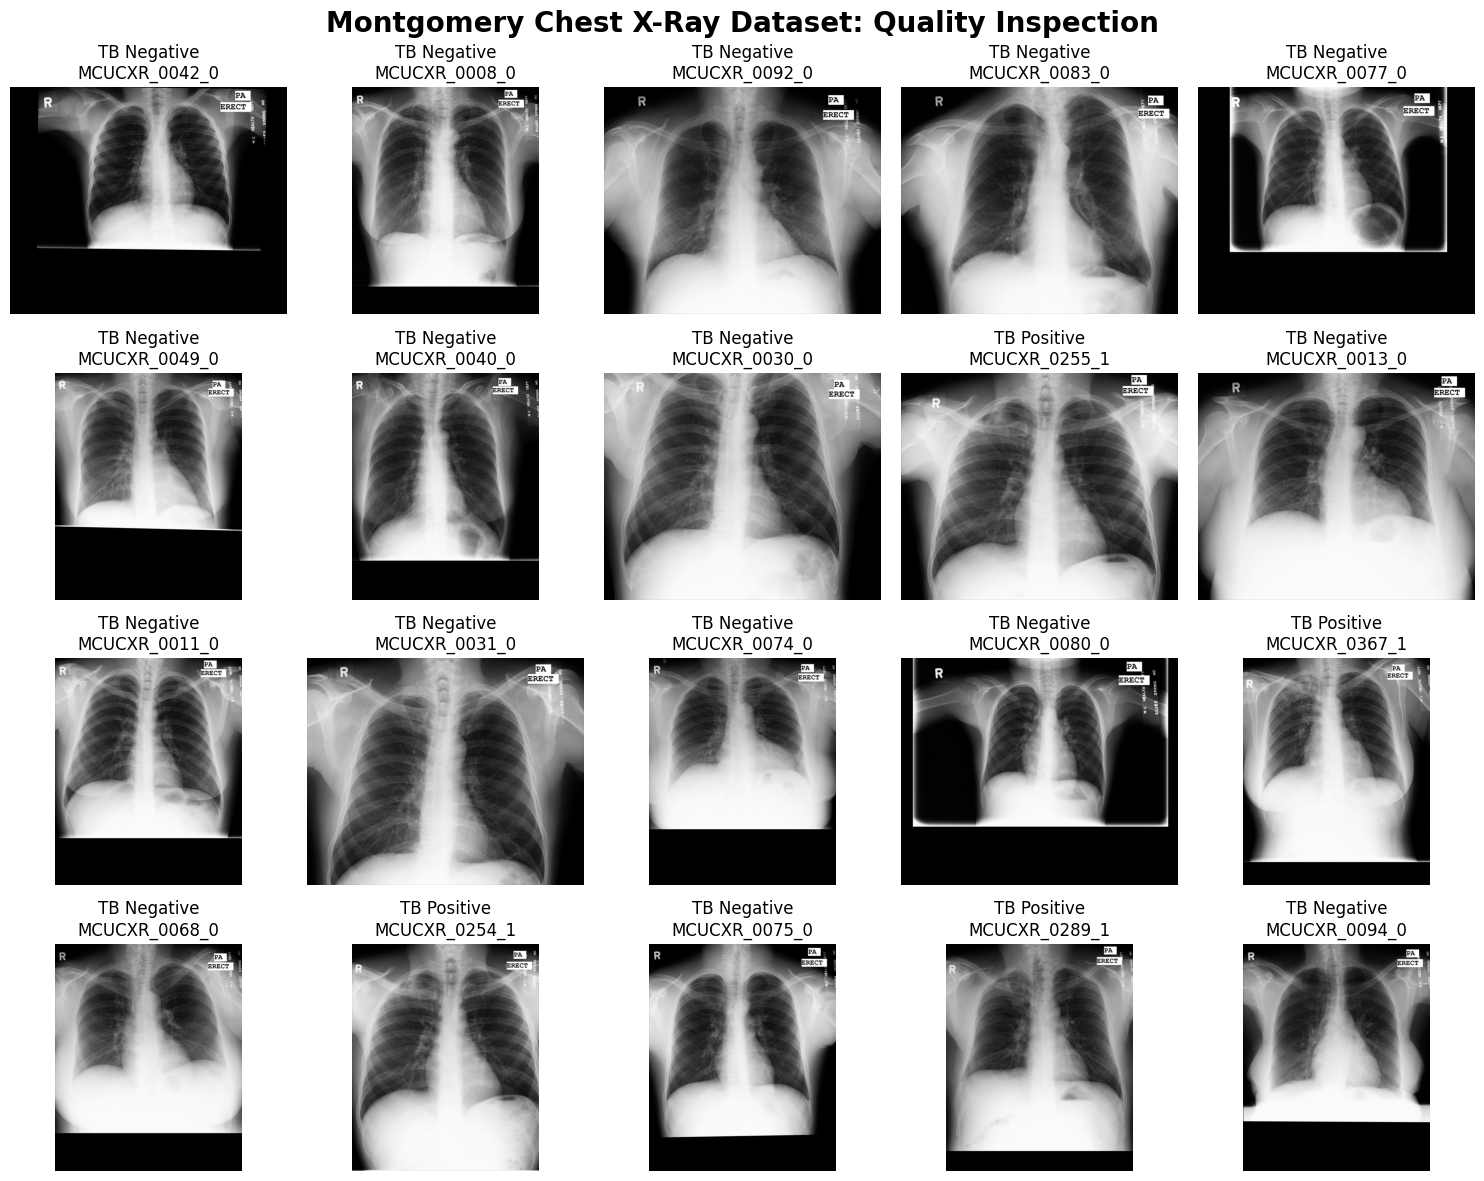

In [ ]:
#random sample grid for montgomery dataset
first_dataset_files = dataset_files["Montgomery"]

n_samples  = 20

#randomly sample images
sampled_files = random.sample(first_dataset_files, n_samples)

#create grid
fig, axes = plt.subplots(4,5, figsize=(15,12))

fig.suptitle(
    "Montgomery Chest X-Ray Dataset: Quality Inspection",
    fontsize = 20,
    fontweight = "bold"
)

for ax, file_path in zip(axes.flat, sampled_files ):
  img = Image.open(file_path)
  img.thumbnail((1000, 1000))
  filename = file_path.stem
  label_num = filename.split("_")[-1]

#converting binary to label for images
  if label_num == "0":
    label = "TB Negative"
  elif label_num == "1":
    label = "TB Positive"
  else:
    label = "Unknown"

#Display image grid
  ax.imshow(img, cmap ="gray")
  ax.set_title(f"{label}\n{filename}")
  ax.axis("off")

plt.tight_layout()
plt.show()

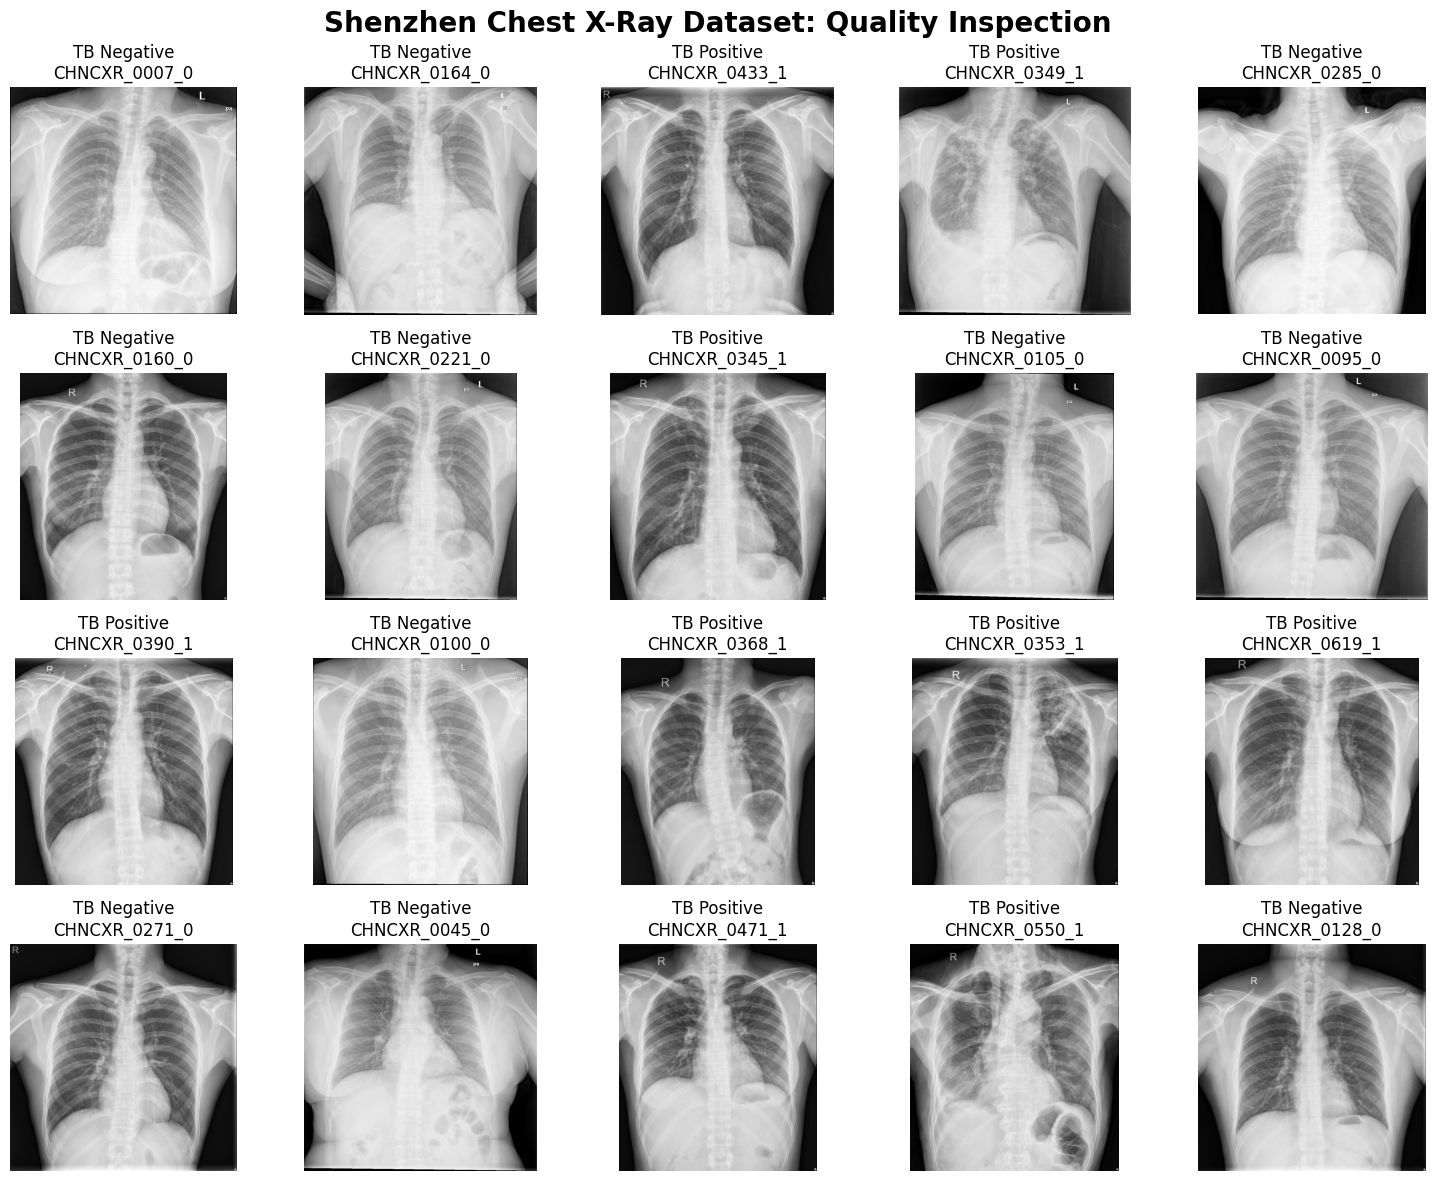

In [ ]:
#random sample grid for Shenzhen dataset
second_dataset_files = dataset_files["Shenzhen"]

n_samples  = 20

#randomly sample images
sampled_files = random.sample(second_dataset_files, n_samples)

#create grid
fig, axes = plt.subplots(4,5, figsize=(15,12))

fig.suptitle(
    "Shenzhen Chest X-Ray Dataset: Quality Inspection",
    fontsize = 20,
    fontweight = "bold"
)

for ax, file_path in zip(axes.flat, sampled_files ):
  img = Image.open(file_path)
  img.thumbnail((1000, 1000))
  filename = file_path.stem
  label_num = filename.split("_")[-1]

#converting binary to label for images
  if label_num == "0":
    label = "TB Negative"
  elif label_num == "1":
    label = "TB Positive"
  else:
    label = "Unknown"

#Display image grid
  ax.imshow(img, cmap ="gray")
  ax.set_title(f"{label}\n{filename}")
  ax.axis("off")

plt.tight_layout()
plt.show()

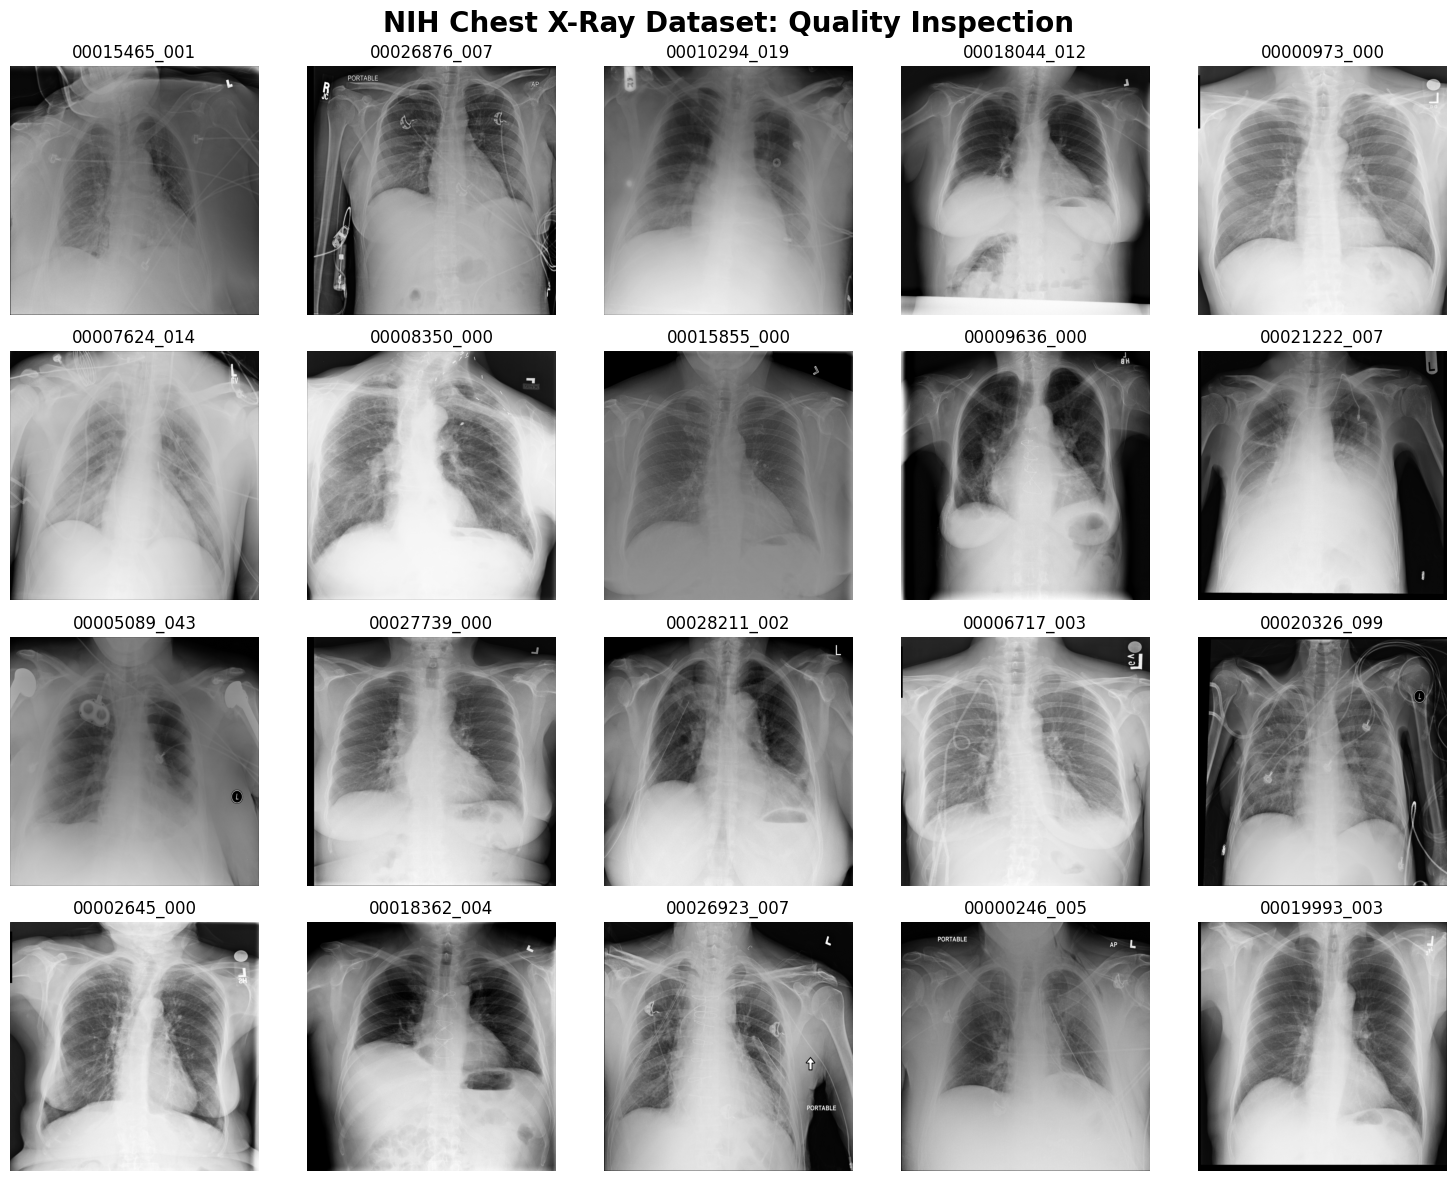

In [ ]:
#random sample grid for NIH dataset
third_dataset_files = dataset_files["NIH"]

n_samples  = 20

#randomly sample images
sampled_files = random.sample(third_dataset_files, n_samples)

#create grid
fig, axes = plt.subplots(4,5, figsize=(15,12))

fig.suptitle(
    "NIH Chest X-Ray Dataset: Quality Inspection",
    fontsize = 20,
    fontweight = "bold"
)

for ax, file_path in zip(axes.flat, sampled_files ):
  img = Image.open(file_path)
  img.thumbnail((1000, 1000))
  filename = file_path.stem

#Display image grid
  ax.imshow(img, cmap ="gray")
  ax.set_title(filename)
  ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# FINAL DATA QUALITY & CLEANING SUMMARY

import pandas as pd
import os

# Results established by the completed quality checks
quality_summary = pd.DataFrame({
    "Metric": [
        "Total images assessed",
        "Montgomery images",
        "Shenzhen images",
        "NIH images",
        "Unreadable/corrupted images detected",
        "Exact duplicate files detected",
        "Montgomery images visually sampled",
        "Shenzhen images visually sampled",
        "NIH images visually sampled",
        "Total images visually sampled"
    ],
    "Result": [
        112920,
        138,
        662,
        112120,
        0,
        0,
        20,
        20,
        20,
        60
    ]
})

display(quality_summary)

print("=" * 65)
print("DATA QUALITY & CLEANING VERIFICATION")
print("=" * 65)

print("""
Dataset coverage
----------------
Montgomery:      138 images
Shenzhen:        662 images
NIH:         112,120 images
Total:       112,920 images

Integrity checks
----------------
Unreadable/corrupted images detected: 0
Exact duplicate files detected:       0

Visual inspection
-----------------
Montgomery sampled: 20
Shenzhen sampled:   20
NIH sampled:        20
Total sampled:      60

Duplicate detection method
--------------------------
Exact file duplicates were assessed using MD5 hashing.
This check does not claim to detect visually similar or
near-duplicate images with different binary contents.
""")

print("=" * 65)
print("DATA QUALITY CHECKS COMPLETED")
print("=" * 65)

,Metric,Result
0,Total images assessed,112920
1,Montgomery images,138
2,Shenzhen images,662
3,NIH images,112120
4,Unreadable/corrupted images detected,0
5,Exact duplicate files detected,0
6,Montgomery images visually sampled,20
7,Shenzhen images visually sampled,20
8,NIH images visually sampled,20
9,Total images visually sampled,60


DATA QUALITY & CLEANING VERIFICATION

Dataset coverage
----------------
Montgomery:      138 images
Shenzhen:        662 images
NIH:         112,120 images
Total:       112,920 images

Integrity checks
----------------
Unreadable/corrupted images detected: 0
Exact duplicate files detected:       0

Visual inspection
-----------------
Montgomery sampled: 20
Shenzhen sampled:   20
NIH sampled:        20
Total sampled:      60

Duplicate detection method
--------------------------
Exact file duplicates were assessed using MD5 hashing.
This check does not claim to detect visually similar or
near-duplicate images with different binary contents.

DATA QUALITY CHECKS COMPLETED
